In [48]:
#EDA Notebook

#Imports  color schema, and Seeding
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image,ImageStat
from collections import Counter
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

random.seed(42)
np.random.seed(42)


In [49]:
#Basic info on the dataset, class names and stuff like that


PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "data" / "raw" / "NSL"

IMAGE_EXTENSION = ".jpg"

BACKGROUND_CATEGORIES = [
    p.name for p in DATASET_DIR.iterdir()
    if p.is_dir()
]

CLASS_NAMES = sorted([
    p.name for p in (DATASET_DIR / BACKGROUND_CATEGORIES[0]).iterdir()
    if p.is_dir()
])


print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)


Number of classes: 36
Classes: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '4', '5', '6', '7', '8', '9']


In [50]:

structure_records = []

for background in BACKGROUND_CATEGORIES:

    background_dir = DATASET_DIR / background

    classes = sorted([
        p.name for p in background_dir.iterdir()
        if p.is_dir()
    ])

    missing_classes = sorted(set(CLASS_NAMES) - set(classes))
    additional_classes = sorted(set(classes) - set(CLASS_NAMES))

    structure_records.append({
        "Background": background,
        "Number of Classes": len(classes),
        "Missing Classes": missing_classes,
        "Additional Classes": additional_classes,
        "Structure Valid": (
            len(missing_classes) == 0
            and len(additional_classes) == 0
        )
    })

structure_df = pd.DataFrame(structure_records)



In [51]:
records = []

for background in BACKGROUND_CATEGORIES:

    for class_name in CLASS_NAMES:

        class_dir = Path(f"{DATASET_DIR}//{background}//{class_name}")

        images = list(class_dir.glob("*.jpg"))

        records.append({
            "Background": background,
            "Class": class_name,
            "Image Count": len(images)
        })

dataset_df = pd.DataFrame(records)


print("Total images:", dataset_df["Image Count"].sum())
print("Total classes:", len(CLASS_NAMES))
print("Background categories:", len(BACKGROUND_CATEGORIES))

Total images: 54000
Total classes: 36
Background categories: 2


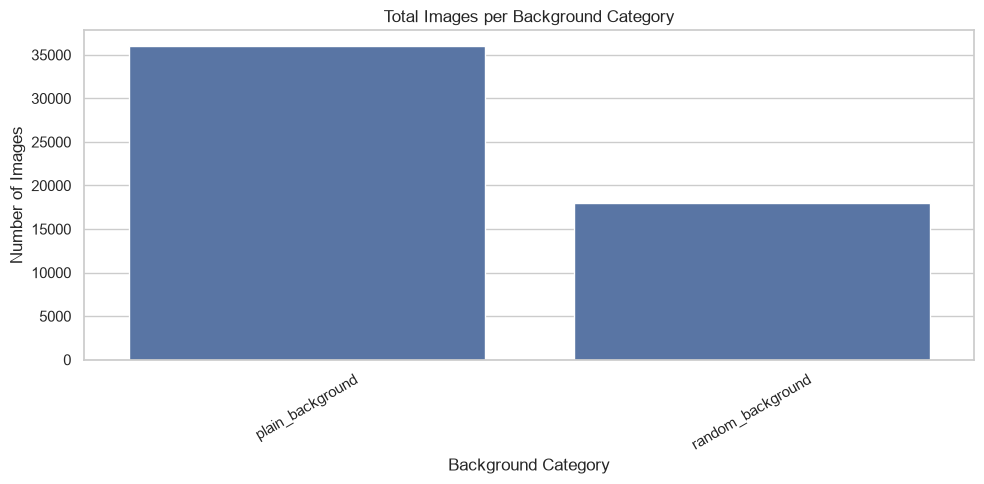

In [52]:

background_counts = (
    dataset_df.groupby("Background")["Image Count"]
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(10, 5))

sns.barplot(
    x=background_counts.index,
    y=background_counts.values
)

plt.title("Total Images per Background Category")
plt.xlabel("Background Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


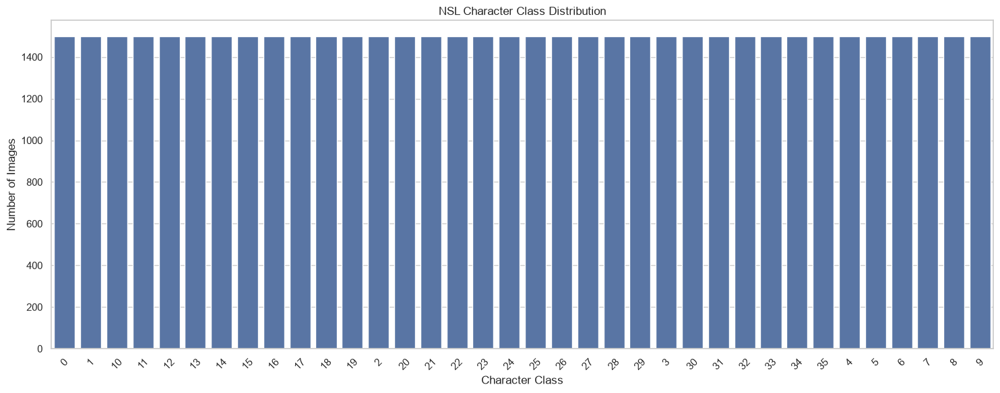

Maximum class count: 1500
Minimum class count: 1500
Average class count: 1500.0


In [53]:

class_counts = (
    dataset_df.groupby("Class")["Image Count"]
    .sum()
    .reindex(CLASS_NAMES, fill_value=0)
)


plt.figure(figsize=(15, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("NSL Character Class Distribution")
plt.xlabel("Character Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Maximum class count:", class_counts.max())
print("Minimum class count:", class_counts.min())
print("Average class count:", round(class_counts.mean(), 2))


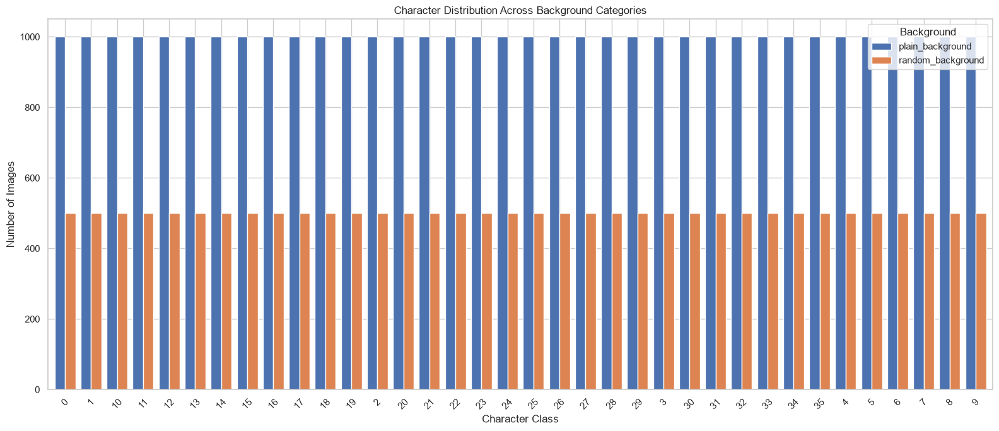

In [54]:

background_distribution = dataset_df.pivot(
    index="Class",
    columns="Background",
    values="Image Count"
).fillna(0)


background_distribution.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("Character Distribution Across Background Categories")
plt.xlabel("Character Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend(title="Background")
plt.tight_layout()
plt.show()


In [55]:
image_records = []
corrupted_images = []

for background in BACKGROUND_CATEGORIES:

    for class_name in CLASS_NAMES:

        class_dir = DATASET_DIR / background / class_name

        for image_path in class_dir.glob("*.jpg"):

            try:
                with Image.open(image_path) as img:

                    width, height = img.size
                    image_format = img.format

                    grayscale = img.convert("L")
                    brightness = ImageStat.Stat(grayscale).mean[0]
                    contrast = ImageStat.Stat(grayscale).stddev[0]

                    img.verify()

                image_records.append({
                    "filename": image_path.name,
                    "background": background,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "resolution": width * height,
                    "aspect_ratio": width / height,
                    "file_size_kb": image_path.stat().st_size / 1024,
                    "brightness": brightness,
                    "contrast": contrast,
                    "format": image_format
                })

            except Exception as error:
                corrupted_images.append({
                    "path": str(image_path),
                    "error": str(error)
                })

images_df = pd.DataFrame(image_records)

print("Valid images:", len(images_df))
print("Corrupted images:", len(corrupted_images))

Valid images: 54000
Corrupted images: 0


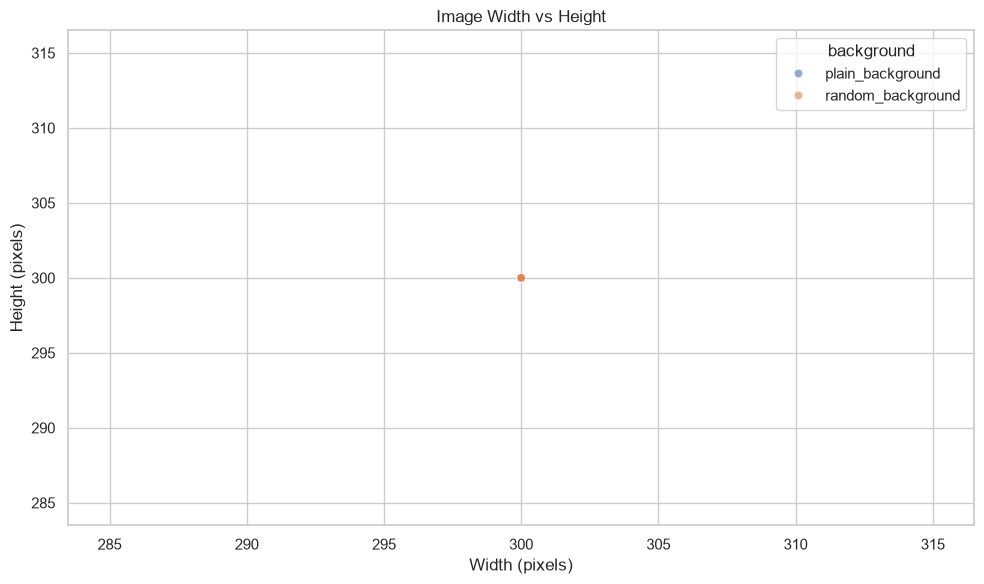

In [56]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=images_df,
    x="width",
    y="height",
    hue="background",
    alpha=0.6
)

plt.title("Image Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

count    54000.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: aspect_ratio, dtype: float64

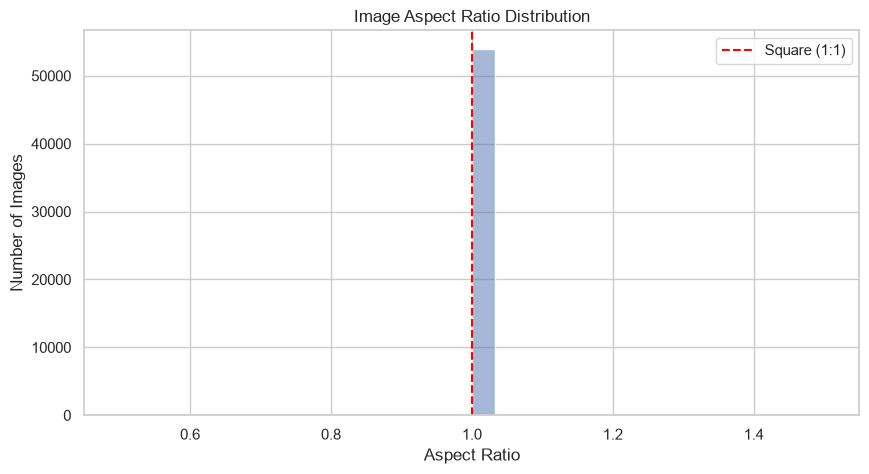

In [57]:
display(images_df["aspect_ratio"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="aspect_ratio",
    bins=30,
    kde=True
)

plt.axvline(
    1,
    color="red",
    linestyle="--",
    label="Square (1:1)"
)

plt.title("Image Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

count    54000.000000
mean        18.855011
std          5.993127
min          8.755859
25%         14.656250
50%         17.236816
75%         20.498291
max         39.568359
Name: file_size_kb, dtype: float64

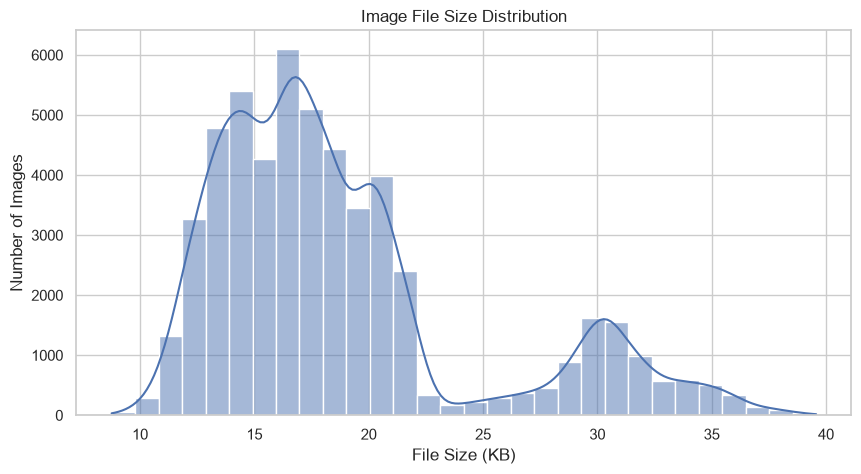

In [58]:
display(images_df["file_size_kb"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="file_size_kb",
    bins=30,
    kde=True
)

plt.title("Image File Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Number of Images")
plt.show()

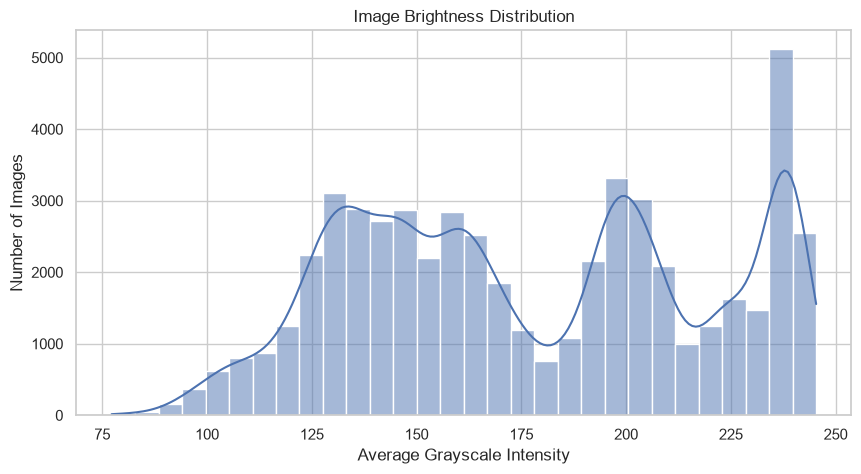

In [59]:


plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="brightness",
    bins=30,
    kde=True
)

plt.title("Image Brightness Distribution")
plt.xlabel("Average Grayscale Intensity")
plt.ylabel("Number of Images")
plt.show()


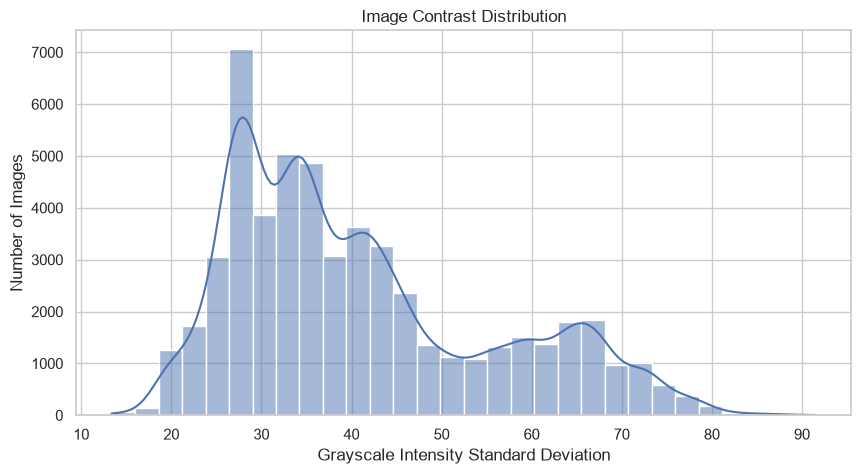

In [60]:


plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="contrast",
    bins=30,
    kde=True
)

plt.title("Image Contrast Distribution")
plt.xlabel("Grayscale Intensity Standard Deviation")
plt.ylabel("Number of Images")
plt.show()


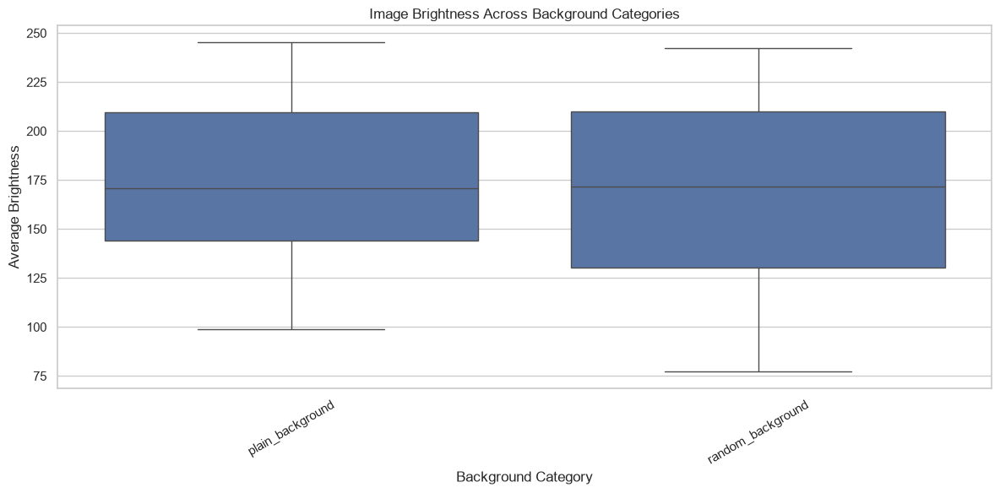

In [61]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=images_df,
    x="background",
    y="brightness"
)

plt.title("Image Brightness Across Background Categories")
plt.xlabel("Background Category")
plt.ylabel("Average Brightness")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


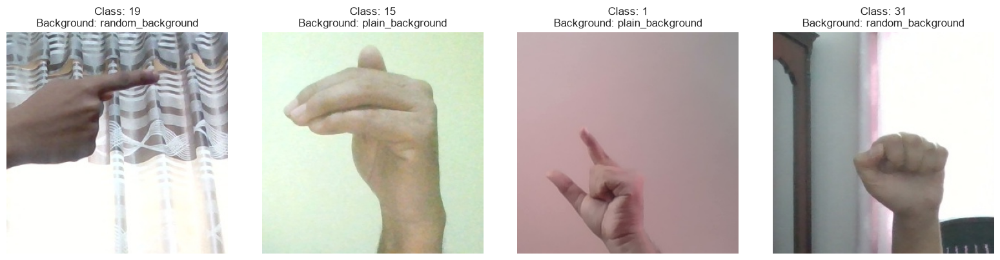

In [62]:

def visualize_random_samples(samples=16):

    image_paths = list(DATASET_DIR.rglob("*.jpg"))

    selected = random.sample(
        image_paths,
        min(samples, len(image_paths))
    )

    cols = 4
    rows = int(np.ceil(len(selected) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(16, rows * 4)
    )

    axes = np.array(axes).flatten()

    for ax, path in zip(axes, selected):

        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Class: {path.parent.name}\n"
            f"Background: {path.parent.parent.name}"
        )

        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_random_samples(4)


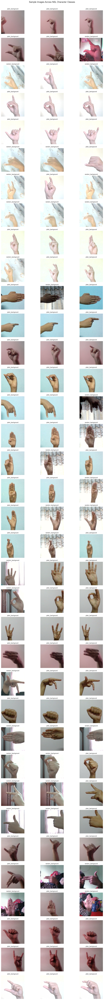

In [63]:

def visualize_classes(samples_per_class=3):

    fig, axes = plt.subplots(
        len(CLASS_NAMES),
        samples_per_class,
        figsize=(12, len(CLASS_NAMES) * 2.5)
    )

    for i, class_name in enumerate(CLASS_NAMES):

        class_images = []

        for background in BACKGROUND_CATEGORIES:

            class_dir = DATASET_DIR / background / class_name

            class_images.extend(list(class_dir.glob("*.jpg")))

        selected = random.sample(
            class_images,
            min(samples_per_class, len(class_images))
        )

        for j in range(samples_per_class):

            ax = axes[i, j]

            if j < len(selected):

                with Image.open(selected[j]) as img:
                    ax.imshow(img.convert("RGB"))

                ax.set_title(
                    selected[j].parent.parent.name,
                    fontsize=9
                )

            ax.axis("off")

            if j == 0:
                ax.set_ylabel(
                    f"Class {class_name}",
                    rotation=0,
                    labelpad=40
                )

    plt.suptitle(
        "Sample Images Across NSL Character Classes",
        y=1.001
    )

    plt.tight_layout()
    plt.show()


visualize_classes(samples_per_class=3)


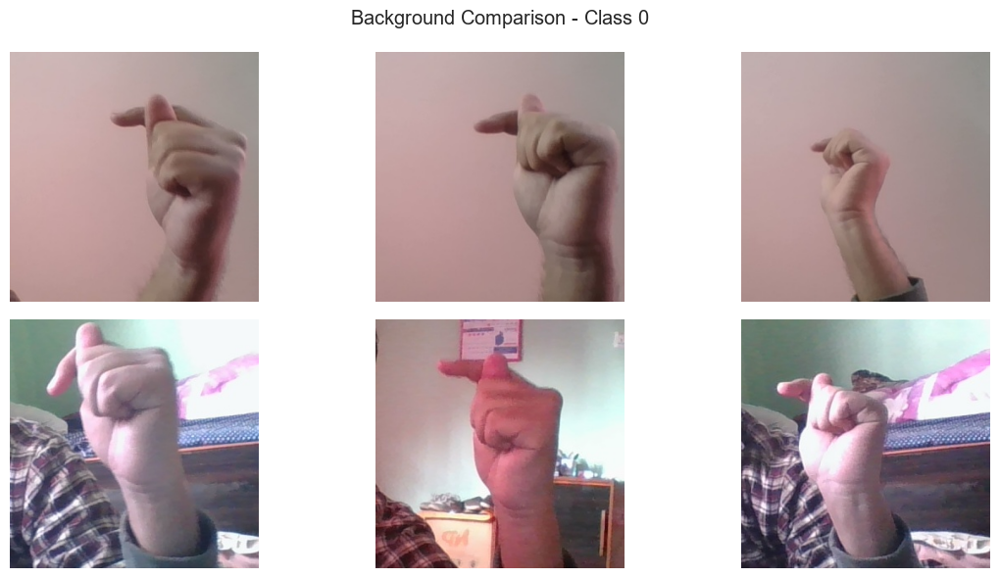

In [64]:

def compare_backgrounds(class_name, samples_per_background=3):

    fig, axes = plt.subplots(
        len(BACKGROUND_CATEGORIES),
        samples_per_background,
        figsize=(12, len(BACKGROUND_CATEGORIES) * 3)
    )

    if len(BACKGROUND_CATEGORIES) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, background in enumerate(BACKGROUND_CATEGORIES):

        class_dir = DATASET_DIR / background / class_name

        image_paths = list(class_dir.glob("*.jpg"))

        selected = random.sample(
            image_paths,
            min(samples_per_background, len(image_paths))
        )

        for j in range(samples_per_background):

            ax = axes[i, j]

            if j < len(selected):

                with Image.open(selected[j]) as img:
                    ax.imshow(img.convert("RGB"))

            ax.axis("off")

            if j == 0:
                ax.set_ylabel(
                    background,
                    rotation=0,
                    labelpad=60
                )

    plt.suptitle(f"Background Comparison - Class {class_name}")
    plt.tight_layout()
    plt.show()


# Change the class number to inspect another character
compare_backgrounds(CLASS_NAMES[0])


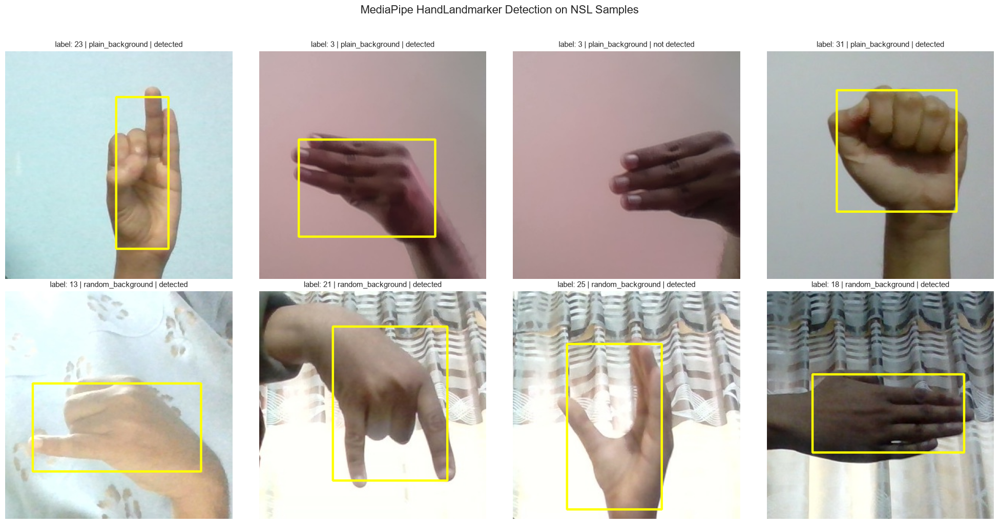

In [65]:
# MediaPipe HandLandmarker Visualization

DATASET_DIR = PROJECT_DIR / "data" / "raw"
ANNOTATIONS = PROJECT_DIR / "data" / "labels.csv"
# Load labels.csv
labels_path = PROJECT_DIR / "data" / "labels.csv"
df = pd.read_csv(labels_path)

# Build HandLandmarker
model_path = str(PROJECT_DIR / "models" / "hand_landmarker.task")
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5
)
detector = vision.HandLandmarker.create_from_options(options)


# Sample 4 plain + 4 random background images
plain_df = df[df['background'] == 'plain_background']
random_df = df[df['background'] == 'random_background']

plain_samples = plain_df.sample(n=4, random_state=42)
random_samples = random_df.sample(n=4, random_state=42)

selected_images = pd.concat([plain_samples, random_samples]).reset_index(drop=True)

# Process and detect
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, row in selected_images.iterrows():
    img_path = PROJECT_DIR / row['image_path']
    
    # Read image with OpenCV
    frame = cv2.imread(str(img_path))
    if frame is None:
        axes[idx].text(0.5, 0.5, 'Failed to load', ha='center', va='center')
        axes[idx].axis('off')
        continue
    
    h, w = frame.shape[:2]
    
    # Convert BGR to RGB for MediaPipe
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Create MediaPipe Image
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
    
    # Detect
    result = detector.detect(mp_image)
    
    # Draw on copy
    annotated = frame.copy()
    detected = len(result.hand_landmarks) > 0
    
    if detected:
        for hand_landmarks in result.hand_landmarks:
            x_coords = [lm.x for lm in hand_landmarks]
            y_coords = [lm.y for lm in hand_landmarks]
            x_min, x_max = int(min(x_coords) * w), int(max(x_coords) * w)
            y_min, y_max = int(min(y_coords) * h), int(max(y_coords) * h)
            cv2.rectangle(annotated, (x_min, y_min), (x_max, y_max), (0, 255, 255), 2)
    
    # Convert back to RGB for matplotlib
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(annotated_rgb)
    status = 'detected' if detected else 'not detected'
    axes[idx].set_title(f"label: {row['label']} | {row['background']} | {status}", fontsize=11)
    axes[idx].axis('off')

plt.suptitle('MediaPipe HandLandmarker Detection on NSL Samples', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()